# Energy curves, carry, storage and spreads — walk-through

Runs end to end in well under two minutes on the frozen public sample (`data/sample`). Every step calls the
package; the published tables and figures come from `scripts/run_results.py`, which uses the same functions
with more Monte Carlo paths.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from energycurves import curves
from energycurves.carry import backtest as bt
from energycurves.carry.signals import deseasonalize, raw_carry
from energycurves.data.stitch import build_curve_panel, slot_returns

T0 = time.time()
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SAMPLE = ROOT / "data" / "sample"
pd.set_option("display.precision", 4)

## 1. Data: EIA contracts 1–4, delivery months rebuilt from the exchange rules

The EIA publishes prices by *slot* (contract 1 = nearest month still trading). `build_curve_panel` drops
stale holiday rows and isolated typos, then attaches each slot's delivery month and time to expiry.

In [2]:
futures = pd.read_parquet(SAMPLE / "futures_daily.parquet")
panel = build_curve_panel(futures)
panel[panel["date"] == "2024-04-05"]

,date,code,contract,delivery_month,last_trade_date,tau,settle
39498,2024-04-05,CL,1,2024-05-01,2024-04-22,0.0466,86.910
39499,2024-04-05,CL,2,2024-06-01,2024-05-21,0.1260,86.100
39500,2024-04-05,CL,3,2024-07-01,2024-06-20,0.2082,85.200
39501,2024-04-05,CL,4,2024-08-01,2024-07-22,0.2959,84.240
73289,2024-04-05,HO,1,2024-05-01,2024-04-30,0.0685,2.773
73290,2024-04-05,HO,2,2024-06-01,2024-05-31,0.1534,2.763
73291,2024-04-05,HO,3,2024-07-01,2024-06-28,0.2301,2.753
73292,2024-04-05,HO,4,2024-08-01,2024-07-31,0.3205,2.747
103114,2024-04-05,NG,1,2024-05-01,2024-04-26,0.0575,1.785
103115,2024-04-05,NG,2,2024-06-01,2024-05-29,0.1479,2.010


## 2. Term structure: roll yield and contango/backwardation

$y^{(1,2)} = (\ln F_1 - \ln F_2)/(\tau_2 - \tau_1)$, positive in backwardation.

In [3]:
ry = curves.roll_yields(panel)
curves.term_structure_summary(ry, "2006-01-01", "2024-04-06")[
    ["code", "mean_y12", "median_y12", "share_backwardation", "share_contango"]
]

,code,mean_y12,median_y12,share_backwardation,share_contango
0,CL,-0.0883,-0.0464,0.2872,0.6667
1,HO,-0.0092,-0.0233,0.3325,0.5849
2,NG,-0.2960,-0.1760,0.1719,0.8039
3,RB,0.0349,0.0493,0.6024,0.3602


In [4]:
season = curves.seasonal_profile(ry, "2006-01-01", "2024-04-06")
season.pivot(index="front_month", columns="code", values="mean_y12").round(3)

code,CL,HO,NG,RB
front_month,,,,
1,-0.115,-0.033,-0.012,-0.072
2,-0.130,0.045,0.282,-0.141
3,-0.167,0.080,-0.070,-1.052
4,-0.110,0.056,-0.278,-0.024
5,-0.219,-0.005,-0.365,-0.004
6,-0.152,-0.030,-0.340,0.121
7,-0.047,-0.048,-0.183,0.129
8,-0.012,-0.077,-0.047,0.197
9,-0.019,-0.067,-0.221,0.729


## 3. Carry: constant-contract returns, seasonally adjusted signal, no look-ahead

In [5]:
signals = deseasonalize(raw_carry(ry))
slot2 = slot_returns(panel, 2)
config = bt.CarryConfig()
inputs = bt.prepare_inputs(slot2, signals, config)
start = bt.common_start(inputs, "2006-01-01")
metrics, costs, navs = bt.evaluate(inputs, start, "2024-04-06", config)
metrics[["strategy", "ann_return", "ann_vol", "sharpe", "t_stat", "max_drawdown"]]

,strategy,ann_return,ann_vol,sharpe,t_stat,max_drawdown
0,TS-raw,-0.0036,0.0576,-0.0629,-0.2472,-0.2256
1,TS-deseason,0.0049,0.0599,0.0811,0.3185,-0.2372
2,XS-raw,-0.0114,0.1307,-0.0873,-0.3427,-0.3391
3,XS-deseason,0.0335,0.1335,0.2510,0.9857,-0.4397
4,LO,-0.0057,0.0834,-0.0689,-0.2705,-0.4163


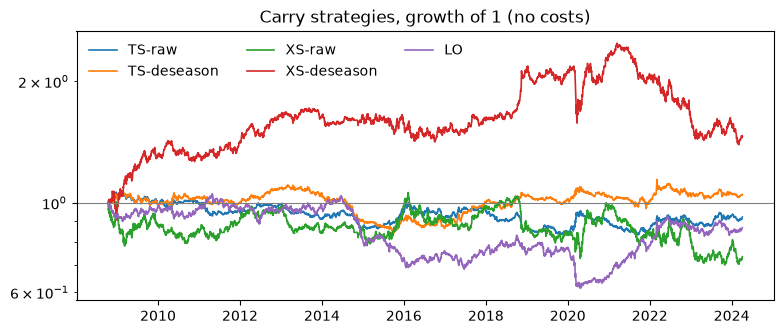

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for name, nav in navs.items():
    ax.plot(nav.index, nav, label=name, linewidth=1.2)
ax.set_yscale("log")
ax.axhline(1, color="grey", linewidth=0.8)
ax.legend(ncols=3, frameon=False)
ax.set_title("Carry strategies, growth of 1 (no costs)")
plt.show()

## 4. Natural-gas storage: intrinsic (LP) and rolling intrinsic (two-factor model)

In [7]:
from energycurves.data.registry import NG_STRIP_SNAPSHOT_DATE
from energycurves.storage.contract import StorageContract, discount_factors, tbill_continuous_rate
from energycurves.storage.curve import strip_forwards
from energycurves.storage.forward_model import calibrate, calibration_sample
from energycurves.storage.intrinsic import intrinsic_lp
from energycurves.storage.rolling import value_storage

contract = StorageContract()  # Apr 2027 - Mar 2028, 6 months to fill, 3 to empty
strip = pd.read_parquet(SAMPLE / "ng_strip_snapshot.parquet")
rates = pd.read_parquet(SAMPLE / "rates_daily.parquet")
t0 = pd.Timestamp(NG_STRIP_SNAPSHOT_DATE)
dtb3 = rates[(rates["series_id"] == "DTB3") & (rates["date"] <= t0)].iloc[-1]["value"]
rate = tbill_continuous_rate(dtb3)
forwards = strip_forwards(strip, contract)
plan = intrinsic_lp(contract, forwards, discount_factors(contract, t0, rate))
pd.DataFrame(
    {"forward": forwards, "inject": plan.injection, "withdraw": plan.withdrawal, "inventory": plan.inventory},
    index=contract.months.astype(str),
).round(3)

,forward,inject,withdraw,inventory
2027-04,2.395,0.167,0.000,0.167
2027-05,2.452,0.167,0.000,0.333
2027-06,2.610,0.167,0.000,0.500
2027-07,2.850,0.167,0.000,0.667
2027-08,2.933,0.167,0.000,0.833
2027-09,2.917,0.167,0.000,1.000
2027-10,2.995,0.000,0.000,1.000
2027-11,3.302,0.000,0.000,1.000
2027-12,3.917,0.000,0.333,0.667
2028-01,4.354,0.000,0.333,0.333


In [8]:
calib = calibrate(calibration_sample(panel, "NG", "2014-04-06", "2024-04-06"))
print(calib.params)
valuation, paths = value_storage(
    contract, forwards, t0, rate, calib.params, n_paths=2000, rng=np.random.default_rng(1)
)
print(f"intrinsic {valuation.intrinsic:.3f}  rolling intrinsic {valuation.rolling_mean:.3f} "
      f"± {valuation.rolling_se:.4f}  extrinsic {valuation.extrinsic_share:+.1%}")
print("RI >= intrinsic on every path:", bool((paths.value >= valuation.intrinsic - 1e-12).all()))

TwoFactorParams(sigma_s=0.5911848779624442, kappa=2.494528255045401, sigma_l=0.4196585372583725, rho=-0.32303941526454444)
intrinsic 1.225  rolling intrinsic 1.270 ± 0.0016  extrinsic +3.7%
RI >= intrinsic on every path: True


## 5. Crack-spread options: Kirk vs Monte Carlo under the same model

In [9]:
from energycurves.spreads.pricing import LEGS, price_grid, snapshot
from energycurves.spreads.schwartz import calibrate_leg, leg_correlations

legs = [calibrate_leg(panel, code) for code in LEGS]
corr = leg_correlations(panel, LEGS).to_numpy()
spread_t0 = pd.Timestamp("2024-04-05")  # last EIA futures settlement
dtb3_2024 = rates[(rates["series_id"] == "DTB3") & (rates["date"] <= spread_t0)].iloc[-1]["value"]
grid = price_grid(
    [snapshot(panel, "2024-04-05", "2024-07-01")], legs, corr, tbill_continuous_rate(dtb3_2024),
    (-10.0, 0.0, 10.0), n_paths=400_000, rng=np.random.default_rng(2),
)
grid[["spread", "strike", "mc_price", "mc_se", "kirk_price", "error_in_se", "error_pct"]]

,spread,strike,mc_price,mc_se,kirk_price,error_in_se,error_pct
0,HO crack (42 HO - CL),20.426,11.2863,0.0079,11.2824,-0.4950,-0.0347
1,HO crack (42 HO - CL),30.426,5.0515,0.0100,5.0486,-0.2909,-0.0576
2,HO crack (42 HO - CL),40.426,1.7862,0.0073,1.7851,-0.1602,-0.0657
3,3-2-1 crack,19.782,10.2294,0.0039,10.2326,0.8485,0.0320
4,3-2-1 crack,29.782,3.2401,0.0063,3.2422,0.3328,0.0649
5,3-2-1 crack,39.782,0.5689,0.0034,0.5802,3.3567,1.9910


## 6. The same data in SQL (DuckDB)

In [10]:
from energycurves.db import build_database, run_query

con = build_database()  # in memory, from data/sample
run_query(con, "30_term_structure", start="2006-01-01", end="2024-04-06", band=0.01)

,code,n_days,first_date,last_date,mean_y12,median_y12,share_backwardation,share_contango,share_flat,mean_y14
0,CL,4555,2006-01-03,2024-04-05,-0.0883,-0.0464,0.2872,0.6667,0.0461,-0.0595
1,HO,4490,2006-01-04,2024-04-05,-0.0092,-0.0233,0.3325,0.5849,0.0826,-0.0163
2,NG,4560,2006-01-03,2024-04-05,-0.2960,-0.1760,0.1719,0.8039,0.0241,-0.2678
3,RB,4525,2006-01-03,2024-04-05,0.0349,0.0493,0.6024,0.3602,0.0373,0.0270


In [11]:
print(f"notebook ran in {time.time() - T0:.1f} s")

notebook ran in 5.1 s
